# Read and plot a line-emission cube

Run the cells from top to bottom using a Python environment with **NumPy** and **Matplotlib**. No snapshot, catalogue, or emissivity table is needed.

The pipeline stores `cube_erg_s[velocity, image_y, image_x]`. Each voxel is the **total intrinsic line luminosity in that bin**, in erg/s. Coordinates are offsets from the selected object's center; velocities have the saved systemic velocity subtracted. These plots are not observed flux or surface brightness, and include no smoothing, broadening, dust, or instrumental response.


In [33]:
from pathlib import Path
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

# Edit this path to display another pipeline output.
# cube_path = Path("/Users/jiaheak/projects/Codex_SIMBA/line_cube_octavius_halo_9_H_1_6562_81A.npz")
cube_path = Path("/Users/jiaheak/projects/Codex_SIMBA/output_line_cube.npz")
if not cube_path.is_file():
    raise FileNotFoundError(cube_path)

# Copy arrays before the archive closes. No pickle loading is needed.
with np.load(cube_path, allow_pickle=False) as archive:
    data = {key: archive[key] for key in archive.files}

cube = np.asarray(data["cube_erg_s"], dtype=float)
x_edges = np.asarray(data["image_x_edges_kpc"], dtype=float)
y_edges = np.asarray(data["image_y_edges_kpc"], dtype=float)
v_edges = np.asarray(data["velocity_edges_kms"], dtype=float)

for name, edges in [("x", x_edges), ("y", y_edges), ("velocity", v_edges)]:
    assert edges.ndim == 1 and edges.size >= 2, f"Invalid {name} edges"
    assert np.all(np.isfinite(edges)) and np.all(np.diff(edges) > 0), f"Invalid {name} edges"
assert cube.shape == (v_edges.size - 1, y_edges.size - 1, x_edges.size - 1)
assert np.all(np.isfinite(cube)), "Cube contains non-finite luminosities"
assert np.all(cube >= 0), "Cube contains negative luminosities"

x_axis = str(data["image_x_axis"].item())
y_axis = str(data["image_y_axis"].item())
line_label = str(data["line_label"].item())
los_axis = str(data["los_axis"].item())

print("Available arrays:", list(data))
print("Cube shape (velocity, y, x):", cube.shape)
print("Line:", line_label)
print("Line of sight:", los_axis)
for key in ["redshift", "selected_particle_count", "center_kpc",
            "systemic_velocity_kms", "box_size_kpc"]:
    if key in data:
        print(f"{key}: {data[key]}")

print(f"Luminosity inside the saved cube: {cube.sum():.6e} erg/s")
print(f"Nonzero voxels: {np.count_nonzero(cube)} / {cube.size}")
if not np.any(cube > 0):
    warnings.warn(
        "The saved cube is entirely zero. Check selected_particle_count first; "
        "if particles were selected, check spatial/velocity coverage and emissivities."
    )

Available arrays: ['cube_erg_s', 'image_x_edges_kpc', 'image_y_edges_kpc', 'velocity_edges_kms', 'image_x_axis', 'image_y_axis', 'los_axis', 'input_source', 'table_type', 'line_label', 'redshift', 'selected_particle_count', 'center_kpc', 'systemic_velocity_kms', 'box_size_kpc']
Cube shape (velocity, y, x): (40, 60, 60)
Line: H  1      6562.81A
Line of sight: z
redshift: 4.440892098500626e-16
selected_particle_count: 2530080
center_kpc: [37422.70220588 45422.05882353 54819.74954044]
systemic_velocity_kms: -23.042242024728225
box_size_kpc: 73529.41176470587
Luminosity inside the saved cube: 9.321199e+38 erg/s
Nonzero voxels: 58336 / 144000


## 1. Integrated line-luminosity map

Sum over velocity bins: `cube.sum(axis=0)` leaves an image in `(y, x)` order.

**Do not multiply by velocity-bin width:** each voxel already contains bin-integrated luminosity. This map includes only the saved velocity range. `pcolormesh` uses the actual edges, including unequal-sized bins.

Positive values can be shown logarithmically; zero pixels are masked in that view. An all-zero map uses a linear scale and is explicitly labelled.

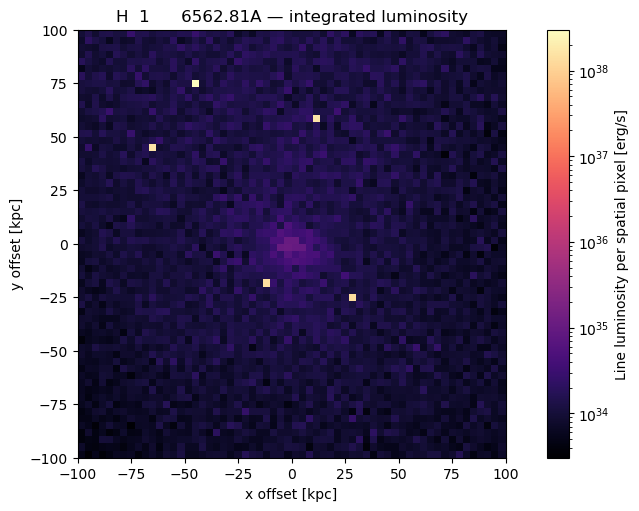

In [34]:
# A shared normalization makes comparisons between channels meaningful.
use_log_scale = True

def luminosity_norm(values, logarithmic=True):
    """Choose a display scale without changing the saved luminosities.

    Returns: norm (matplotlib.colors.Normalize): linear or logarithmic color scale.
    """
    positive = np.asarray(values)[np.asarray(values) > 0]
    if logarithmic and positive.size:
        lower, upper = float(positive.min()), float(positive.max())
        if lower == upper:
            lower, upper = lower / 10, upper * 10
        return LogNorm(vmin=lower, vmax=upper)
    return Normalize(vmin=0, vmax=float(positive.max()) if positive.size else 1)

integrated_map = cube.sum(axis=0)
norm = luminosity_norm(integrated_map, use_log_scale)
display_map = np.ma.masked_less_equal(integrated_map, 0) if isinstance(norm, LogNorm) else integrated_map

fig_map, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
mesh = ax.pcolormesh(x_edges, y_edges, display_map, shading="flat", cmap="magma", norm=norm)
ax.set(xlabel=f"{x_axis} offset [kpc]", ylabel=f"{y_axis} offset [kpc]",
       title=f"{line_label.strip()} — integrated luminosity")
ax.set_aspect("equal")
fig_map.colorbar(mesh, ax=ax, label="Line luminosity per spatial pixel [erg/s]")
if not np.any(integrated_map):
    ax.text(0.5, 0.5, "All pixels are zero", transform=ax.transAxes,
            ha="center", va="center", color="white")
plt.show()

## 2. Spatially integrated spectrum

Summing both image axes gives luminosity **per velocity bin**, in erg/s. This is not luminosity per km/s. To obtain that quantity, divide `spectrum` by `np.diff(v_edges)`.

The spectrum includes only the saved spatial aperture. Its sum and the integrated map's sum must equal the cube's sum.

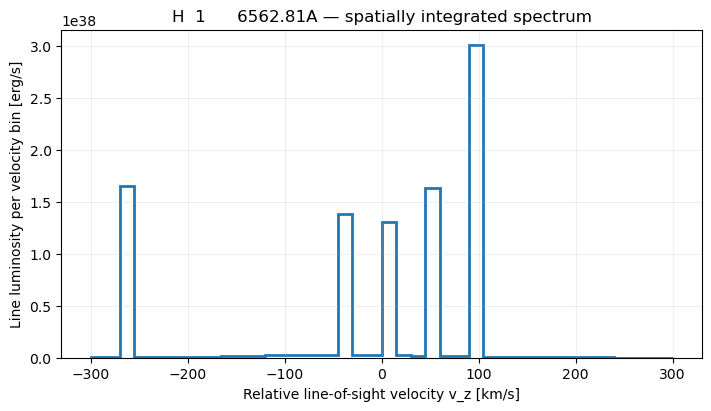

In [35]:
spectrum = cube.sum(axis=(1, 2))
np.testing.assert_allclose(integrated_map.sum(), cube.sum())
np.testing.assert_allclose(spectrum.sum(), cube.sum())

fig_spectrum, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.stairs(spectrum, v_edges, color="tab:blue", linewidth=2)
ax.set(xlabel=f"Relative line-of-sight velocity v_{los_axis} [km/s]",
       ylabel="Line luminosity per velocity bin [erg/s]",
       title=f"{line_label.strip()} — spatially integrated spectrum")
ax.grid(alpha=0.2)
if not np.any(spectrum):
    ax.set_ylim(0, 1)
    ax.text(0.5, 0.6, "No emission in the saved cube", transform=ax.transAxes, ha="center")
plt.show()

## 3. Velocity-channel maps

Each panel shows one velocity bin, with the same color scale across all displayed channels. Change `channel_indices` to choose channels when displaying a larger cube. No interpolation or spatial smoothing is applied.

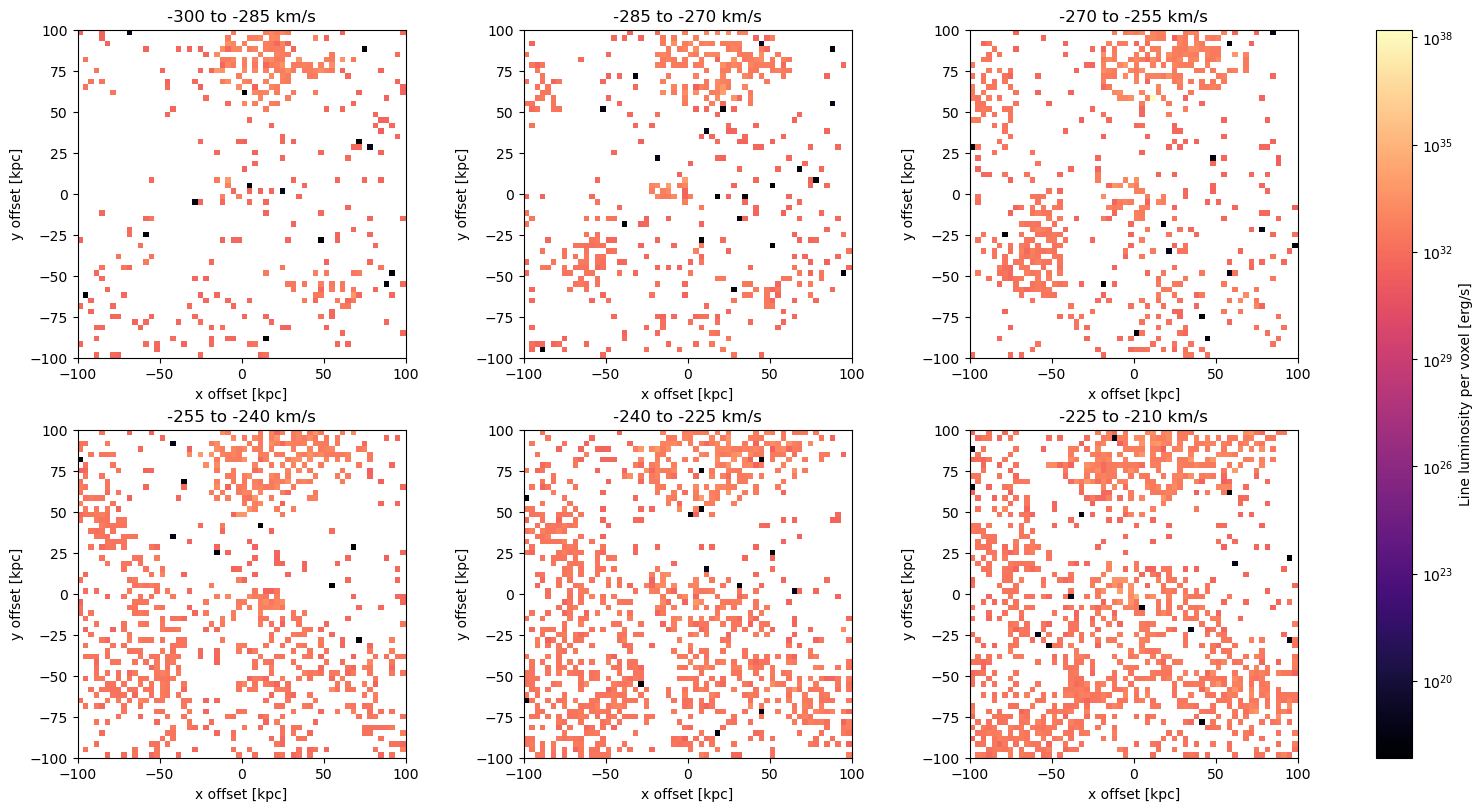

In [36]:
# Show up to six channels by default; e.g. use [0, 3, 5] for a custom subset.
channel_indices = list(range(min(cube.shape[0], 6)))
assert channel_indices, "Select at least one channel"
assert all(isinstance(i, int) and 0 <= i < cube.shape[0] for i in channel_indices)

ncols = min(3, len(channel_indices))
nrows = (len(channel_indices) + ncols - 1) // ncols
fig_channels, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                                  squeeze=False, constrained_layout=True)
norm = luminosity_norm(cube[channel_indices], use_log_scale)
active_axes = []
for ax, index in zip(axes.flat, channel_indices):
    channel = cube[index]
    display_channel = np.ma.masked_less_equal(channel, 0) if isinstance(norm, LogNorm) else channel
    mesh = ax.pcolormesh(x_edges, y_edges, display_channel,
                         shading="flat", cmap="magma", norm=norm)
    ax.set(xlabel=f"{x_axis} offset [kpc]", ylabel=f"{y_axis} offset [kpc]",
           title=f"{v_edges[index]:g} to {v_edges[index + 1]:g} km/s")
    ax.set_aspect("equal")
    if not np.any(channel):
        ax.text(0.5, 0.5, "All pixels are zero", transform=ax.transAxes,
                ha="center", va="center", color="white")
    active_axes.append(ax)
for ax in list(axes.flat)[len(channel_indices):]:
    ax.set_visible(False)
fig_channels.colorbar(mesh, ax=active_axes, label="Line luminosity per voxel [erg/s]")
plt.show()

## Optional: save the figures

Uncomment the following lines to save PNG files beside the input cube. The NPZ file is never modified.

If `selected_particle_count` is zero, revisit catalogue membership selection before interpreting the emission. If it is nonzero but the cube is empty, investigate the aperture, velocity range, gas luminosities, and catalogue/snapshot consistency. This notebook cannot determine the cause from the cube alone.

In [37]:
# fig_map.savefig(cube_path.with_name("line_integrated_map.png"), dpi=200, bbox_inches="tight")
# fig_spectrum.savefig(cube_path.with_name("line_spectrum.png"), dpi=200, bbox_inches="tight")
# fig_channels.savefig(cube_path.with_name("line_velocity_channels.png"), dpi=200, bbox_inches="tight")